# Plate shake

**The question:** how much does the plate move under the camera, and does it hurt the movement score?

A plate shake of half a pixel is too small to see, but it moves every mite's outline across its pixels and makes a still mite score like a moving one. The plate moves on two time scales, and each one is handled separately:

- **within a recording** (frame to frame, 0.7 s to 1 s): `classes/plate_stabilizer.py` measures each mite's shift from the first frame, takes the median over the mites as the plate's shift and cuts every patch moved back by it (`stabilize_plate: true`);
- **across recordings** (minutes to days): every mite's box is fixed when the mites are detected, so if the plate drifts, the mites drift inside their boxes. Nothing in the movement score corrects for this. `classes/recording_change.py` takes the drift out only when it compares two recordings.

**The measurements**, on every dataset saved in `calibration_data/`, from the recordings themselves (the cached patches are already stabilized and would hide the shake):

1. per recording and frame, each mite's shift from the recording's first frame (phase correlation refined by ECC, as `PlateStabilizer` does it); the plate's shift is the median over every detection;
2. per recording, each mite's image as the mean of its frames, after stabilization; per mite, the shift of that image from the first recording: its **displacement across recordings**. The median over the mites is the plate's drift; what is left over after it is taken out is the mite's own movement.

Shifts are in pixels of the full image (about 2064 × 1544 px).

## Findings

_(to be written after the run)_

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT)]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

import pipeline
from classes import calibration
from classes.analyzer import Analyzer
from classes.app_config import get_default_config
from classes.data_loader import DataLoader
from classes.plate_stabilizer import PlateStabilizer
from classes.recording_change import RecordingChange
from classes.workers import side_by_side

# The project's reporting module switches matplotlib to Agg (no figures) on import.
%matplotlib inline

MARGIN = 8                               # pixels around each box the shifts are measured with (PlateStabilizer's pad)
REACH = MARGIN + pipeline.STABILIZE_MARGIN  # how far past the boxes the frames are read
HALF_PIXEL = 0.5                         # the shake the README calls enough to make a still mite look moving

# Chart style, as in the other notebooks: thin marks, recessive axes and grid, text in ink colours.
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8d8c85"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3dc"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 8.5, "lines.linewidth": 2,
})
pd.set_option("display.precision", 2)

## Measuring every recording

Per dataset: every detection's box is used to measure the plate (as a calibration does), but only the mites not marked *not a mite* are shown mite by mite. A recording not labelled counts as still. This reads every recording once (about a minute for the long run).

In [2]:
stabilizer = PlateStabilizer(MARGIN)
config = get_default_config().mite
METRIC = config.metric
PARAMS = config.params_for(METRIC)
THRESHOLD = config.threshold_for(METRIC)
PAD = Analyzer.roi_padding(METRIC, PARAMS)
print(f"movement score: {METRIC} {PARAMS}, threshold {THRESHOLD:g}")


def measure(dataset_id):
    data = pipeline._read_dataset(dataset_id, pipeline.CALIBRATION_LIBRARY)
    recordings_dir = pipeline._recordings_dir(data["data_dir"], pipeline.CALIBRATION_LIBRARY)
    if not recordings_dir.is_dir():
        recordings_dir = pipeline._dataset_dir(dataset_id, pipeline.CALIBRATION_LIBRARY) / pipeline.RECORDINGS_DIRNAME
    times = np.array(data["times"], dtype=float)
    states = {mite["id"]: calibration.per_recording(data["truth"].get(mite["id"]), len(times)) for mite in data["mites"]}
    boxes = pipeline.mite_boxes(data["mites"])
    ids = list(boxes)
    kept = np.array([not calibration.is_rejected(states[i]) for i in ids])

    x0, y0 = min(b[0] for b in boxes.values()) - REACH, min(b[1] for b in boxes.values()) - REACH
    x_end, y_end = max(b[2] for b in boxes.values()) + REACH, max(b[3] for b in boxes.values()) + REACH
    local = [(x1 - x0, y1 - y0, x2 - x0, y2 - y0) for x1, y1, x2, y2 in boxes.values()]
    loader = DataLoader(recordings_dir, grayscale=False)

    within, images, scores = [], [], []  # per recording: (mites, frames, 2); (mites,) images; (2, mites) scores
    for recording in data["recordings"]:
        frames = loader.load_recording_region(recording["name"], x0, y0, x_end, y_end)
        per_mite = np.array(side_by_side(lambda box: stabilizer._mite_shifts(frames, box), local))
        plate = np.median(per_mite, axis=0)
        within.append(per_mite)
        images.append([PlateStabilizer.cut(frames, box, MARGIN, plate).mean(axis=(0, 3)) for box in local])
        # the movement score, the patch cut as the plate moved it (raw) and moved back (stabilized)
        scores.append([side_by_side(lambda box: Analyzer._motion_score(PlateStabilizer.cut(frames, box, PAD, shifts),
                                                                      METRIC, PARAMS), local)
                       for shifts in (np.zeros_like(plate), plate)])
    images = [[images[r][m] for r in range(len(times))] for m in range(len(ids))]  # per mite, per recording

    # each mite's displacement from its image in the first recording
    across = np.array(side_by_side(lambda mite: [PlateStabilizer._shift(mite[0], image) for image in mite], images))
    labels = np.array([states[i] for i in ids], dtype=object)
    return {"name": data["name"], "times": times, "ids": ids, "kept": kept,
            "centres": np.array([((b[0] + b[2]) / 2, (b[1] + b[3]) / 2) for b in boxes.values()]),
            "moving": labels == calibration.MOVING,
            "still": labels == calibration.STILL,
            "within": within, "images": images,
            "raw": np.array(scores)[:, 0].T, "stabilized": np.array(scores)[:, 1].T,  # (mites, recordings)
            "across": across,                              # (mites, recordings, 2)
            "drift": np.median(across, axis=0),            # the plate's, (recordings, 2)
            "steps": RecordingChange(MARGIN).plate_shifts(images)}  # the plate's from each recording to the next


summaries = sorted(pipeline.list_calibration_datasets(), key=lambda s: s["id"])
runs = {}
for summary in summaries:
    run = measure(summary["id"])
    runs[run["name"]] = run
    print(f"{run['name']}: {len(run['ids'])} detections ({run['kept'].sum()} mites), {len(run['times'])} recordings "
          f"{np.median(np.diff(run['times'])):g} min apart, {run['within'][0].shape[1]} frames each")
LONG = max(runs, key=lambda name: len(runs[name]["times"]))

movement score: outline_variability {'relative': 0.0, 'width': 1.5, 'pad': 16}, threshold 0.31
ground_truth_60min: 34 detections (29 mites), 6 recordings 5 min apart, 30 frames each
ground_truth_90min: 31 detections (28 mites), 6 recordings 5 min apart, 30 frames each
sample_data: 30 detections (29 mites), 6 recordings 5 min apart, 30 frames each
test_run_2026-09-08_Mathis_last_dsRNA: 60 detections (59 mites), 295 recordings 10 min apart, 10 frames each


## 1. Shake within a recording

Per recording, the plate's shift in each frame from the first frame. The **shake** of a recording is the largest of them (length of the shift vector). The **precision** of the measurement is how far a mite labelled still strays from the plate's shift: the RMS over its frames of (its shift − the plate's).

In [3]:
rows = []
for name, run in runs.items():
    plate = np.array([np.median(w, axis=0) for w in run["within"]])           # (recordings, frames, 2)
    shake = np.hypot(*np.moveaxis(plate, -1, 0)).max(axis=1)                   # (recordings,)
    run["shake"] = shake
    spread = np.array([np.sqrt((np.hypot(*np.moveaxis(w - np.median(w, axis=0), -1, 0)) ** 2).mean(axis=1))
                       for w in run["within"]]).T                              # (mites, recordings)
    run["spread"] = spread
    still = run["still"] & run["kept"][:, None]
    rows.append({"dataset": name, "recordings": len(shake),
                 "shake: median (px)": np.median(shake), "90%": np.percentile(shake, 90), "largest": shake.max(),
                 f"recordings > {HALF_PIXEL} px": int((shake > HALF_PIXEL).sum()),
                 "still mite vs plate: median RMS (px)": np.median(spread[still]),
                 "99%": np.percentile(spread[still], 99)})
display(pd.DataFrame(rows).style.format(precision=3).hide(axis="index"))

dataset,recordings,shake: median (px),90%,largest,recordings > 0.5 px,still mite vs plate: median RMS (px),99%
ground_truth_60min,6,0.014,0.017,0.020,0,0.018,0.025
ground_truth_90min,6,0.011,0.012,0.012,0,0.018,0.033
sample_data,6,0.011,0.013,0.013,0,0.019,0.033
test_run_2026-09-08_Mathis_last_dsRNA,295,0.115,0.213,0.260,0,0.019,0.030


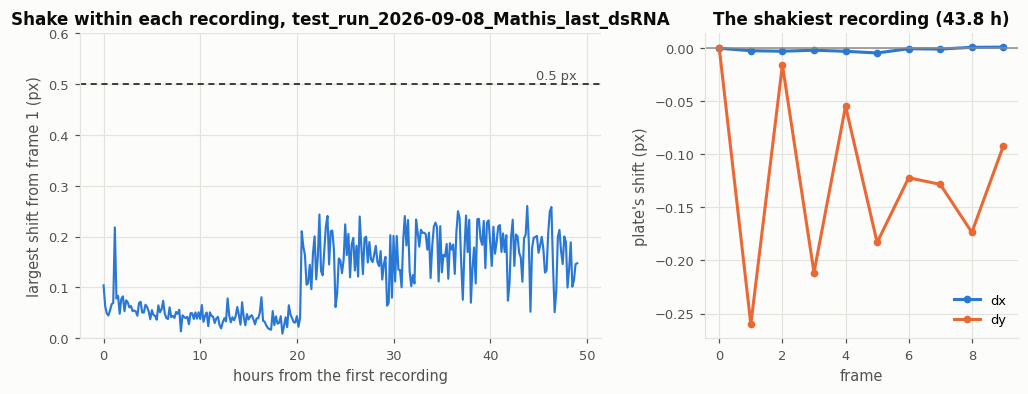

the shake changes level at recording 124 (20.5 h, 09 Sep 10:34): median 0.044 px before, 0.174 px after


In [4]:
run = runs[LONG]
hours = run["times"] / 60
plate = np.array([np.median(w, axis=0) for w in run["within"]])
worst = int(np.argmax(run["shake"]))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [5, 3], "wspace": 0.25})
ax.plot(hours, run["shake"], color=BLUE, linewidth=1.4)
ax.axhline(HALF_PIXEL, color=INK, linewidth=1, linestyle=(0, (4, 3)))
ax.annotate(f"{HALF_PIXEL} px", (hours[-1], HALF_PIXEL), xytext=(0, 3), textcoords="offset points", ha="right",
            fontsize=8.5, color=MUTED)
ax.set(xlabel="hours from the first recording", ylabel="largest shift from frame 1 (px)",
       title=f"Shake within each recording, {LONG}", ylim=(0, max(HALF_PIXEL * 1.2, run["shake"].max() * 1.1)))
frames = np.arange(plate.shape[1])
ax2.plot(frames, plate[worst, :, 0], color=BLUE, marker="o", markersize=4, label="dx")
ax2.plot(frames, plate[worst, :, 1], color=ORANGE, marker="o", markersize=4, label="dy")
ax2.axhline(0, color=GREY, linewidth=1)
ax2.set(xlabel="frame", ylabel="plate's shift (px)", title=f"The shakiest recording ({hours[worst]:.1f} h)")
ax2.legend()
plt.show()

# where the shake changes level: the split with the least squared deviation from the two parts' means
shake = run["shake"]
cost = [((shake[:k] - shake[:k].mean()) ** 2).sum() + ((shake[k:] - shake[k:].mean()) ** 2).sum()
        for k in range(5, len(shake) - 5)]
CHANGE = 5 + int(np.argmin(cost))
first = pipeline._read_dataset(next(s["id"] for s in summaries if s["id"].startswith(LONG)),
                               pipeline.CALIBRATION_LIBRARY)["recordings"][0]["name"]
clock = DataLoader.parse_start_time(first) + pd.Timedelta(minutes=run["times"][CHANGE])
print(f"the shake changes level at recording {CHANGE + 1} ({hours[CHANGE]:.1f} h, {clock:%d %b %H:%M}): "
      f"median {np.median(shake[:CHANGE]):.3f} px before, {np.median(shake[CHANGE:]):.3f} px after")

## 2. Mite displacement across recordings

Each mite's displacement from its own image in the first recording, against time. Thin grey lines: one per mite. Blue: the plate's drift, the median over all detections. A mite that walks leaves its box and gives a meaningless shift (phase correlation finds anything up to half the patch), so the lines that jump are mites moving, not the plate.

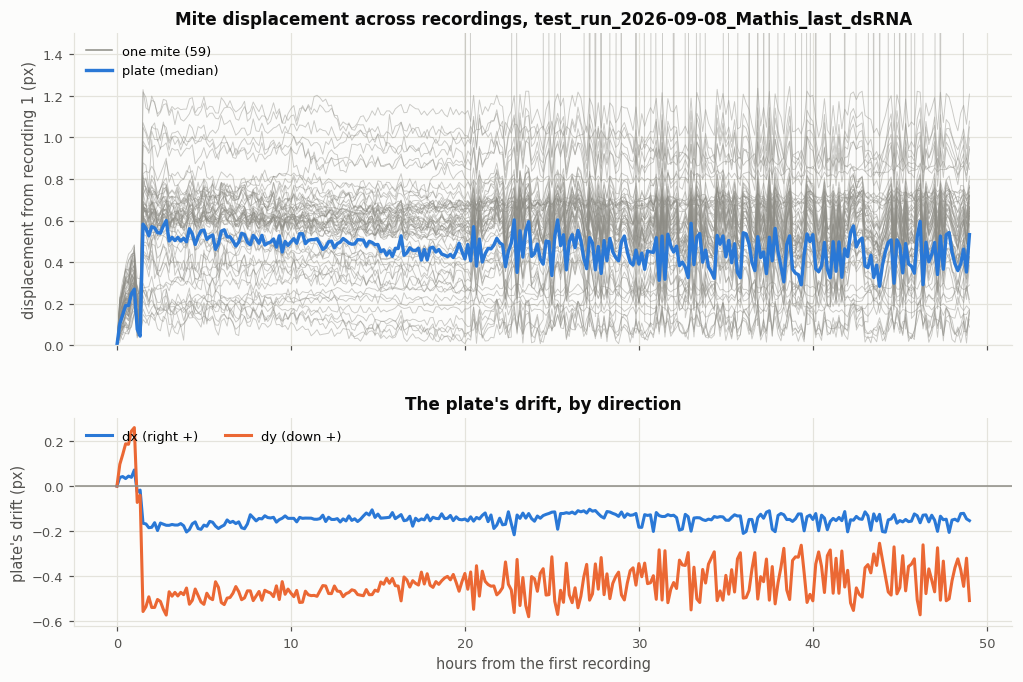

In [5]:
def displacement_figure(run, title):
    hours = run["times"] / 60
    kept = run["kept"]
    across = run["across"][kept]
    drift = run["drift"]
    distance = np.hypot(across[..., 0], across[..., 1])
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"hspace": 0.28,
                                                                                    "height_ratios": [3, 2]})
    for line in distance:
        ax.plot(hours, line, color=GREY, linewidth=0.6, alpha=0.45)
    ax.plot(hours, np.hypot(*drift.T), color=BLUE, linewidth=2.2)
    ax.plot([], [], color=GREY, linewidth=1, label=f"one mite ({kept.sum()})")
    ax.plot([], [], color=BLUE, linewidth=2.2, label="plate (median)")
    top = max(1.5, np.percentile(distance, 97) * 1.15)
    ax.set(ylabel="displacement from recording 1 (px)", ylim=(0, top), title=title)
    ax.legend(loc="upper left")
    ax2.plot(hours, drift[:, 0], color=BLUE, label="dx (right +)")
    ax2.plot(hours, drift[:, 1], color=ORANGE, label="dy (down +)")
    ax2.axhline(0, color=GREY, linewidth=1)
    ax2.set(xlabel="hours from the first recording", ylabel="plate's drift (px)",
            title="The plate's drift, by direction")
    ax2.legend(loc="upper left", ncols=2)
    plt.show()


displacement_figure(runs[LONG], f"Mite displacement across recordings, {LONG}")

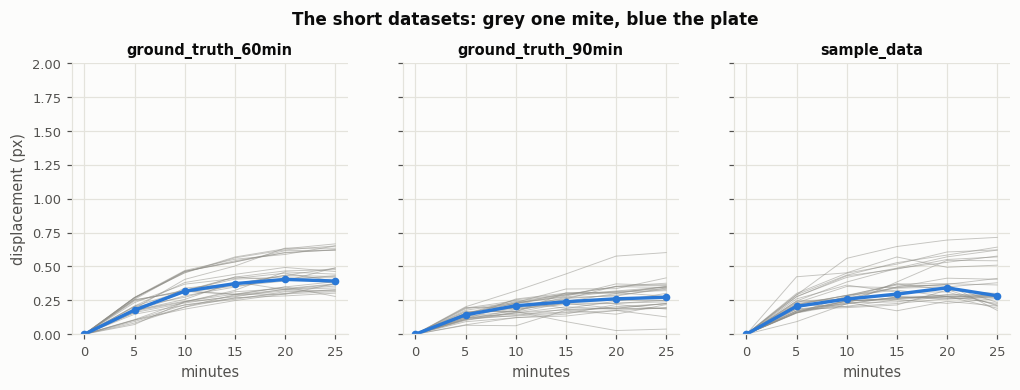

dataset,hours,plate's drift: largest (px),at the end,recording to next: median (px),largest,steps > 0.5 px
ground_truth_60min,0.42,0.40,0.39,0.08,0.18,0
ground_truth_90min,0.42,0.27,0.27,0.05,0.14,0
sample_data,0.42,0.34,0.28,0.05,0.21,0
test_run_2026-09-08_Mathis_last_dsRNA,49.00,0.60,0.53,0.05,0.54,1


In [6]:
fig, axes = plt.subplots(1, len(runs) - 1, figsize=(11, 3.2), sharey=True)
for ax, (name, run) in zip(np.atleast_1d(axes), [(n, r) for n, r in runs.items() if n != LONG]):
    minutes = run["times"]
    for line in np.hypot(*np.moveaxis(run["across"][run["kept"]], -1, 0)):
        ax.plot(minutes, line, color=GREY, linewidth=0.6, alpha=0.5)
    ax.plot(minutes, np.hypot(*run["drift"].T), color=BLUE, linewidth=2.2, marker="o", markersize=4)
    ax.set(title=name, xlabel="minutes")
    ax.title.set_fontsize(9.5)
np.atleast_1d(axes)[0].set_ylabel("displacement (px)")
np.atleast_1d(axes)[0].set_ylim(0, 2)
fig.suptitle("The short datasets: grey one mite, blue the plate", fontsize=11, fontweight="bold", color=INK, y=1.03)
plt.show()

rows = []
for name, run in runs.items():
    drift = np.hypot(*run["drift"].T)
    steps = np.hypot(*run["steps"].T)
    rows.append({"dataset": name, "hours": run["times"][-1] / 60, "plate's drift: largest (px)": drift.max(),
                 "at the end": drift[-1], "recording to next: median (px)": np.median(steps),
                 "largest": steps.max(), f"steps > {HALF_PIXEL} px": int((steps > HALF_PIXEL).sum())})
display(pd.DataFrame(rows).style.format(precision=2).hide(axis="index"))

### The mites' own displacement, the plate taken out

Each mite's displacement from the first recording minus the plate's drift, one row per mite, sorted by its last labelled movement (black line; the mites without one never moved). After its last movement a mite that lies dead should stay at its place: if the rows stay pale there, the median is a fair measure of the plate, and the plate's drift is what is left for a dead mite to show.

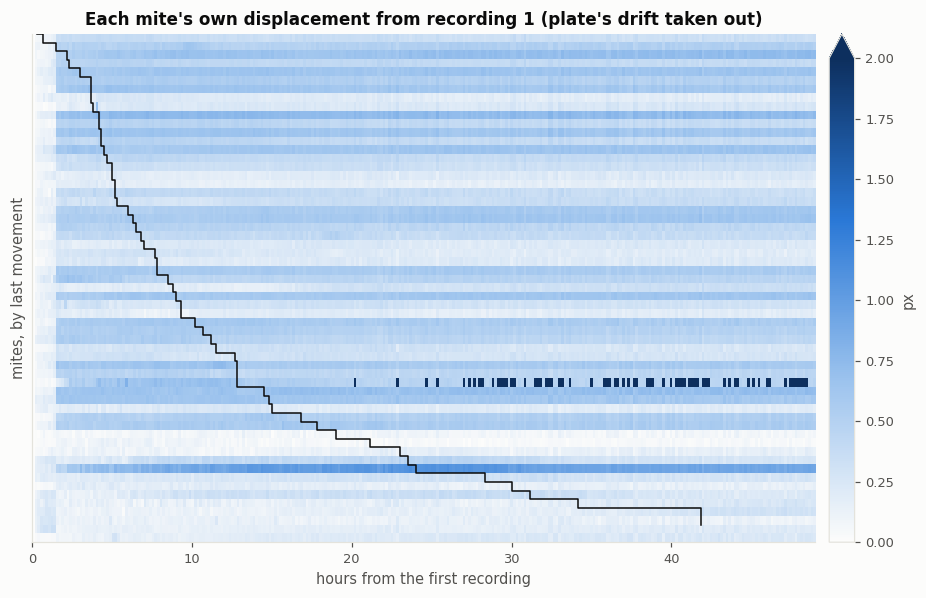

after its last movement (13583 mite-recordings): a mite's own displacement from where it stopped has median 0.04 px, 99% below 0.46 px


In [7]:
run = runs[LONG]
kept = run["kept"]
hours = run["times"] / 60
own = np.hypot(*np.moveaxis(run["across"][kept] - run["drift"], -1, 0))   # (mites, recordings)
moving = run["moving"][kept]
moved = moving.any(axis=1)
n_mites, n_recordings = moving.shape
last = np.where(moved, n_recordings - 1 - np.argmax(moving[:, ::-1], axis=1), -1)
order = np.argsort(np.where(moved, last, n_recordings), kind="stable")

shade = LinearSegmentedColormap.from_list("shift", ["#fcfcfb", "#9cc3ee", BLUE, "#0d2f5e"])
fig, ax = plt.subplots(figsize=(11, 6))
drawn = ax.imshow(own[order], aspect="auto", cmap=shade, vmin=0, vmax=2, interpolation="nearest",
                  extent=(hours[0], hours[-1], n_mites, 0))
n_moved = int(moved.sum())
ax.step(np.append(hours[last[order][:n_moved]], hours[last[order][n_moved - 1]]), np.arange(n_moved + 1),
        color=INK, linewidth=1, where="post")
ax.set(xlabel="hours from the first recording", ylabel="mites, by last movement", yticks=[],
       title="Each mite's own displacement from recording 1 (plate's drift taken out)", xlim=(hours[0], hours[-1]))
ax.grid(visible=False)
fig.colorbar(drawn, ax=ax, pad=0.015, label="px", extend="max")
plt.show()

# after the last movement: how far a dead mite sits from where the plate says it should
after = np.arange(n_recordings)[None] > last[:, None]
settled = own - own[np.arange(n_mites), np.minimum(last + 1, n_recordings - 1)][:, None]  # from its place when it stopped
print(f"after its last movement ({after.sum()} mite-recordings): a mite's own displacement from where it stopped "
      f"has median {np.median(np.abs(settled[after])):.2f} px, 99% below {np.percentile(np.abs(settled[after]), 99):.2f} px")

## 3. Is the drift one shift for the whole plate?

The stabilizer and the recording comparison both assume the plate moves rigidly: one shift for every mite. If it turned or grew (warming of the plate or the lens), mites far apart would drift differently. Checked on the long run's mites that are dead by a reference recording (the first one by which 80% of the mites that moved had made their last movement): each one's displacement from there to the last recording, set against where it lies on the plate.

45 mites dead by recording 99 (16.3 h) to the end (49.0 h)
plate's shift in that time (median): dx -0.04, dy -0.03 px
left over after one shift for all: RMS 0.06 px; after an affine map: 0.06 px
affine part: scale +0.01 px per 1000 px, turn -0.10 arc minutes


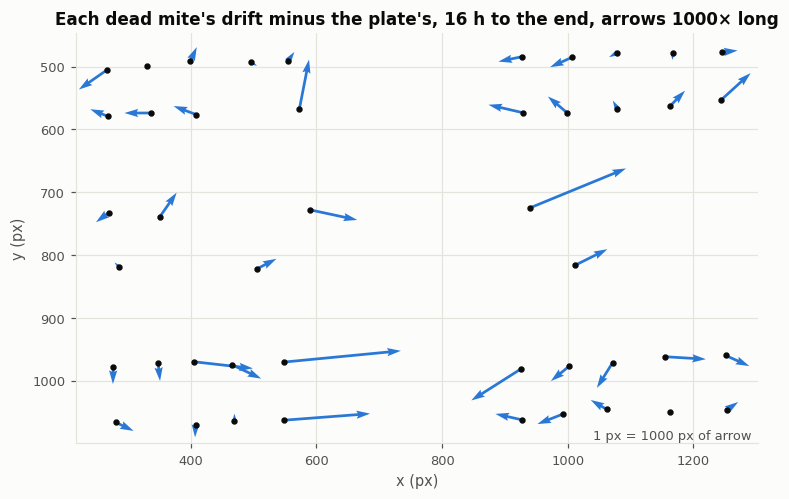

In [8]:
run = runs[LONG]
kept = np.flatnonzero(run["kept"])
moving = run["moving"][kept]
moved = moving.any(axis=1)
last = np.where(moved, moving.shape[1] - 1 - np.argmax(moving[:, ::-1], axis=1), 0)
reference = int(np.percentile(last[moved], 80))
dead = kept[moved & (last < reference)]
images = [run["images"][m] for m in dead]
shift = np.array([PlateStabilizer._shift(mite[reference], mite[-1]) for mite in images])
centres = run["centres"][dead]

# a rigid shift, against an affine map (shift, turn, stretch): displacement = A @ (position - centre) + t
X = np.column_stack([centres - centres.mean(axis=0), np.ones(len(dead))])
coef, *_ = np.linalg.lstsq(X, shift, rcond=None)
rigid = shift - np.median(shift, axis=0)
affine = shift - X @ coef
A = coef[:2].T
print(f"{len(dead)} mites dead by recording {reference + 1} ({run['times'][reference] / 60:.1f} h) "
      f"to the end ({run['times'][-1] / 60:.1f} h)")
print(f"plate's shift in that time (median): dx {np.median(shift[:, 0]):+.2f}, dy {np.median(shift[:, 1]):+.2f} px")
print(f"left over after one shift for all: RMS {np.sqrt((rigid ** 2).sum(axis=1).mean()):.2f} px; "
      f"after an affine map: {np.sqrt((affine ** 2).sum(axis=1).mean()):.2f} px")
print(f"affine part: scale {1e3 * (A[0, 0] + A[1, 1]) / 2:+.2f} px per 1000 px, "
      f"turn {np.degrees((A[1, 0] - A[0, 1]) / 2) * 60:+.2f} arc minutes")

fig, ax = plt.subplots(figsize=(8, 6))
scale = 1000  # arrows drawn 1000 times their length
ax.quiver(centres[:, 0], centres[:, 1], rigid[:, 0], rigid[:, 1], angles="xy", scale_units="xy", scale=1 / scale,
          color=BLUE, width=0.004)
ax.scatter(centres[:, 0], centres[:, 1], s=10, color=INK, zorder=3)
ax.set(xlabel="x (px)", ylabel="y (px)", aspect="equal",
       title=f"Each dead mite's drift minus the plate's, {run['times'][reference] / 60:.0f} h to the end, arrows {scale}× long")
ax.invert_yaxis()
ax.annotate(f"1 px = {scale} px of arrow", (0.99, 0.01), xycoords="axes fraction", ha="right", fontsize=8.5,
            color=MUTED)
plt.show()

### The jump early in the long run

The plate's largest step from one recording to the next. Each mite's own step across it is one point. If the plate moved as one, the points form a tight cloud around the plate's step. Every mite is still alive then, so a few may have moved by themselves.

largest step: recording 9 to 10 (1.3 to 1.5 h): plate dx -0.25, dy -0.48 px
mites within 0.1 px of the plate's step: 4 of 59; median distance 0.32 px; 16 labelled moving in one of the two recordings


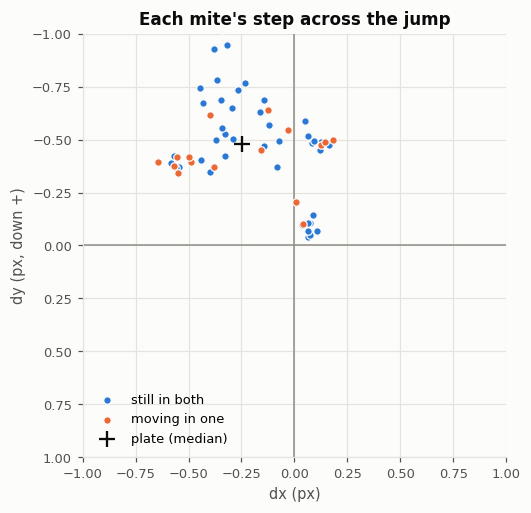

In [9]:
run = runs[LONG]
kept = np.flatnonzero(run["kept"])
jump = int(np.argmax(np.hypot(*run["steps"].T)))
step = np.array([PlateStabilizer._shift(run["images"][m][jump], run["images"][m][jump + 1]) for m in kept])
plate_step = run["steps"][jump]
off = np.hypot(*(step - plate_step).T)
moving_then = run["moving"][kept][:, jump] | run["moving"][kept][:, jump + 1]
print(f"largest step: recording {jump + 1} to {jump + 2} ({run['times'][jump] / 60:.1f} to {run['times'][jump + 1] / 60:.1f} h): "
      f"plate dx {plate_step[0]:+.2f}, dy {plate_step[1]:+.2f} px")
print(f"mites within 0.1 px of the plate's step: {(off < 0.1).sum()} of {len(kept)}; median distance {np.median(off):.2f} px; "
      f"{moving_then.sum()} labelled moving in one of the two recordings")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(*step[~moving_then].T, s=24, color=BLUE, edgecolor="#fcfcfb", linewidth=0.8, label="still in both", zorder=3)
ax.scatter(*step[moving_then].T, s=24, color=ORANGE, edgecolor="#fcfcfb", linewidth=0.8, label="moving in one", zorder=3)
ax.scatter(*plate_step, s=120, marker="+", color=INK, linewidth=1.5, label="plate (median)", zorder=4)
ax.axhline(0, color=GREY, linewidth=1)
ax.axvline(0, color=GREY, linewidth=1)
lim = max(1, np.percentile(np.abs(step), 95) * 1.2)
ax.set(xlim=(-lim, lim), ylim=(lim, -lim), aspect="equal", xlabel="dx (px)", ylabel="dy (px, down +)",
       title="Each mite's step across the jump")
ax.legend(loc="lower left")
plt.show()

## 4. Does the shake reach the movement score?

Part way through the long run the shake doubles, and nothing else about the plate changes at that time. That makes a natural test. Every mite's movement score is computed in every recording, two ways: with the patch cut as the camera saw it (**raw**), and with it moved back by the plate's shift (**stabilized**, which is what the app does). Only mites taken as dead are counted, at least 500 minutes after their last labelled movement (as in `dead_mite_change.ipynb`). A dead mite does not move, so every score above the threshold is a false call.

patch,dead mite-recordings,n,score: median,95%,called moving (> 0.31)
raw,before the change,1447,0.035,0.080,0.0%
raw,after the change,8759,0.059,0.184,0.5%
stabilized,before the change,1447,0.034,0.077,0.0%
stabilized,after the change,8759,0.039,0.101,0.0%


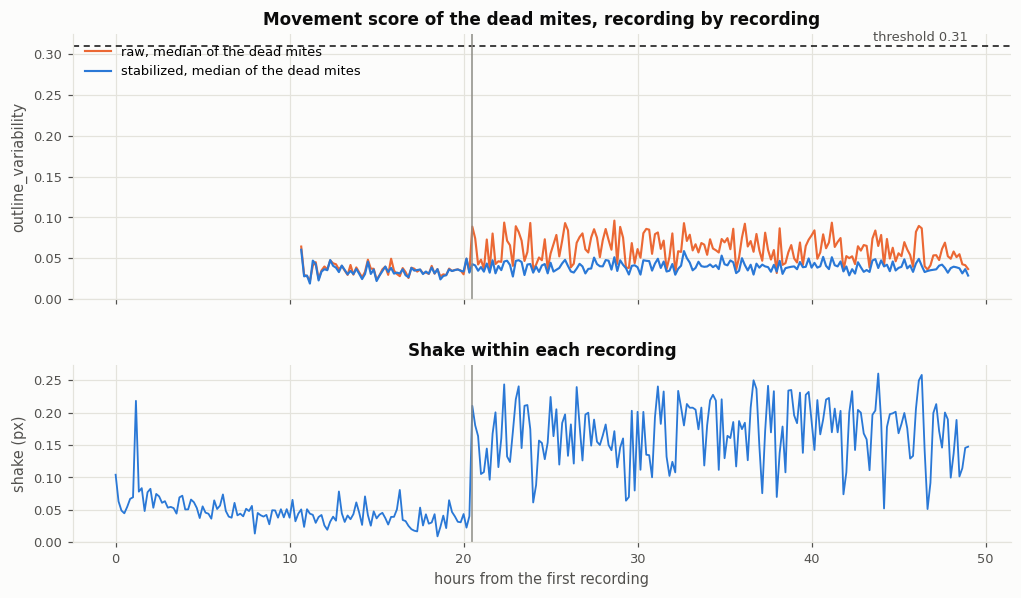

In [10]:
run = runs[LONG]
kept = run["kept"]
hours = run["times"] / 60
moving = run["moving"][kept]
moved = moving.any(axis=1)
last = np.where(moved, moving.shape[1] - 1 - np.argmax(moving[:, ::-1], axis=1), 0)
dead = moved[:, None] & (run["times"][None] - run["times"][last][:, None] >= 500)
after = np.arange(len(hours))[None] >= CHANGE

rows = []
for kind in ("raw", "stabilized"):
    score = run[kind][kept]
    for label, part in (("before the change", ~after), ("after the change", after)):
        mask = dead & part
        rows.append({"patch": kind, "dead mite-recordings": label, "n": int(mask.sum()),
                     "score: median": np.median(score[mask]), "95%": np.percentile(score[mask], 95),
                     f"called moving (> {THRESHOLD:g})": (score[mask] > THRESHOLD).mean()})
display(pd.DataFrame(rows).style.format({f"called moving (> {THRESHOLD:g})": "{:.1%}"}, precision=3).hide(axis="index"))

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"hspace": 0.3, "height_ratios": [3, 2]})
has = dead.sum(axis=0) >= 5
for kind, colour in (("raw", ORANGE), ("stabilized", BLUE)):
    score = np.where(dead, run[kind][kept], np.nan)
    ax.plot(hours[has], np.nanmedian(score[:, has], axis=0), color=colour, linewidth=1.4,
            label=f"{kind}, median of the dead mites")
ax.axhline(THRESHOLD, color=INK, linewidth=1, linestyle=(0, (4, 3)))
ax.annotate(f"threshold {THRESHOLD:g}", (hours[-1], THRESHOLD), xytext=(0, 3), textcoords="offset points", ha="right",
            fontsize=8.5, color=MUTED)
ax.axvline(hours[CHANGE], color=GREY, linewidth=1)
ax.set(ylabel=METRIC, title="Movement score of the dead mites, recording by recording", ylim=(0, None))
ax.legend(loc="upper left")
ax2.plot(hours, run["shake"], color=BLUE, linewidth=1.2)
ax2.axvline(hours[CHANGE], color=GREY, linewidth=1)
ax2.set(xlabel="hours from the first recording", ylabel="shake (px)", title="Shake within each recording", ylim=(0, None))
plt.show()